# ColdChain Monitor — первинний аналіз даних
Повністю синтетичні дані. Усі графіки й результати обчислено з фіксованим seed. Мітки не підтверджують безпечність молока. Код клітинок виконано у Python; ноутбук сумісний із Jupyter.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
# Run from repository root or ml/notebooks.
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent.parent
if not (ROOT / 'ml').is_dir(): raise RuntimeError('Run from repository root or ml/notebooks')
for folder in ['data/raw','data/processed','reports/figures','reports/results']: (ROOT / folder).mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(24)
SEED, SHIPMENTS, STEPS, DT = 24, 600, 144, 10/60
print({'seed':SEED,'shipments':SHIPMENTS,'steps':STEPS,'interval_minutes':10})


{'seed': 24, 'shipments': 600, 'steps': 144, 'interval_minutes': 10}


## 1 Генерація
600 незалежних партій, по 144 вимірювання через 10 хвилин. Прогноз на 12-й годині стосується симуляційного результату на 24-й годині. Ідентифікатор і дата партії не є ознаками моделі. Межі 2–8 °C — сценарні налаштування, не норматив.

In [2]:
raw_rows, outcomes = [], []
for b in range(SHIPMENTS):
    mode = rng.choice(4, p=[.42,.23,.23,.12])
    temp = 4.5 + .2*b/SHIPMENTS + rng.normal(0,.35) + rng.normal(0,.35,STEPS)
    if mode:
        start = int(rng.integers(12,96))
        duration = int(rng.integers(8,25) if mode==1 else rng.integers(36,100))
        temp[start:min(STEPS,start+duration)] += rng.uniform(3,7) if mode==1 else rng.uniform(6,13)
    age = float(rng.uniform(0,30))
    # Q10-style synthetic exposure, not a calibrated microbiological model.
    exposure = age + float(np.sum(2**((temp-4)/10))*DT)
    label = int(exposure + rng.normal(0,4) > 56)
    hum = np.clip(73 - .8*(temp-4) + rng.normal(0,3,STEPS),30,99)
    observed = temp.copy()
    observed[rng.random(STEPS)<.003] = 45.0
    observed[rng.random(STEPS)<.01] = np.nan
    hum[rng.random(STEPS)<.015] = np.nan
    for k in range(STEPS):
        raw_rows.append((b,k,pd.Timestamp('2026-01-01',tz='UTC')+pd.Timedelta(days=b//5,minutes=10*k),observed[k],hum[k],age))
    outcomes.append((b,label,exposure))
raw = pd.DataFrame(raw_rows,columns=['shipment_id','sample_index','timestamp','temperature_c','humidity_pct','initial_age_h'])
labels = pd.DataFrame(outcomes,columns=['shipment_id','simulated_spoilage','latent_final_exposure'])
raw.to_csv(ROOT/'data/raw/telemetry.csv',index=False)
labels.to_csv(ROOT/'data/raw/simulation_outcomes.csv',index=False)
print('Raw shape:',raw.shape,'; unique shipments:',raw.shipment_id.nunique())
print('Missing:',raw.isna().sum().to_dict())
print('Duplicate keys:',int(raw.duplicated(['shipment_id','sample_index']).sum()))
print('Sensor spikes:',int((raw.temperature_c>30).sum()))
print('Positive labels:',int(labels.simulated_spoilage.sum()))


Raw shape: (86400, 6) ; unique shipments: 600
Missing: {'shipment_id': 0, 'sample_index': 0, 'timestamp': 0, 'temperature_c': 842, 'humidity_pct': 1308, 'initial_age_h': 0}
Duplicate keys: 0
Sensor spikes: 231
Positive labels: 88


## 2 Пропуски і викиди
Робочий контроль датчика: температури нижче −5 або вище 30 °C переводяться у пропуски. Це припущення симулятора; справжній діапазон слід конфігурувати за датчиком. Перегріви 8–22 °C залишаються в даних.

Missing before: {'temperature_c': 842, 'humidity_pct': 1308}
Missing after invalidation: {'temperature_c': 1073, 'humidity_pct': 1308}


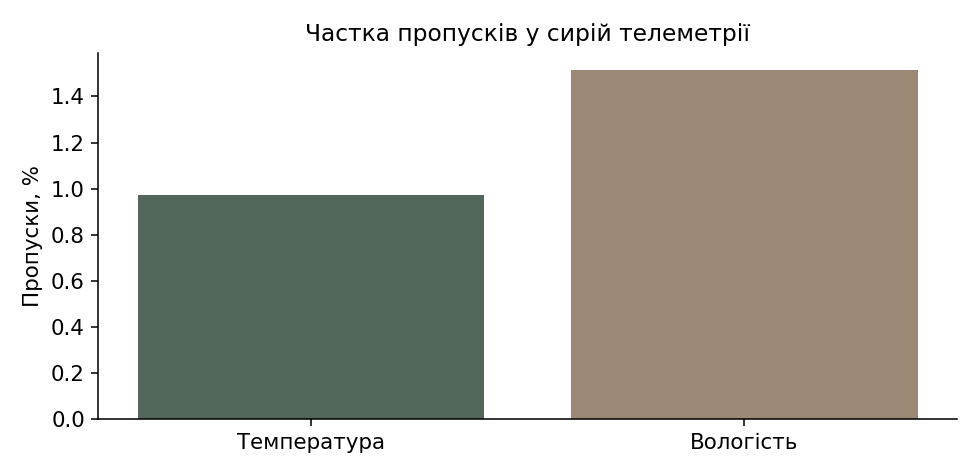

In [3]:
clean = raw.copy()
invalid = ~clean.temperature_c.between(-5,30) & clean.temperature_c.notna()
clean.loc[invalid,'temperature_c'] = np.nan
fig, ax = plt.subplots(figsize=(7,3.4))
cols=['temperature_c','humidity_pct']
ax.bar(['Температура','Вологість'],raw[cols].isna().mean().values*100,color=['#52665a','#9c8975'])
ax.set(ylabel='Пропуски, %',title='Частка пропусків у сирій телеметрії')
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_missing.png');plt.close(fig)
print('Missing before:',raw[cols].isna().sum().to_dict())
print('Missing after invalidation:',clean[cols].isna().sum().to_dict())


Пропуски не заповнюються майбутніми значеннями. Для ознак використовуються наявні виміри першої половини рейсу та індикатор повноти. Партії з менш як 90% валідних температур на практиці йдуть на ручний розгляд.

       temperature_c  humidity_pct
count      85327.000     85092.000
mean           6.142        71.292
std            3.505         4.126
min            2.296        51.297
25%            4.349        69.043
50%            4.742        71.781
75%            5.280        74.102
max           18.890        85.086


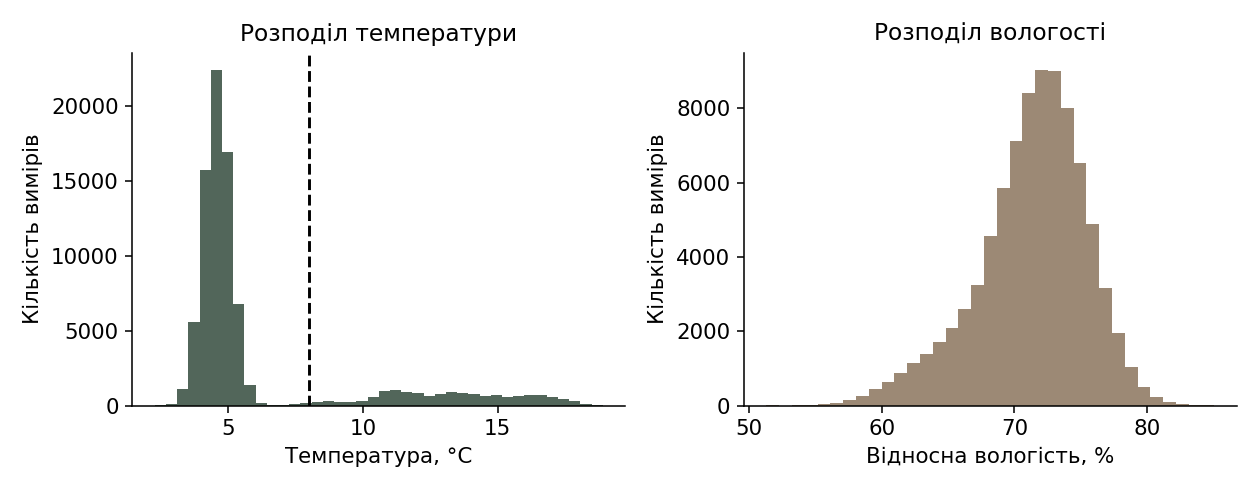

In [4]:
fig, ax = plt.subplots(1,2,figsize=(9,3.5))
ax[0].hist(clean.temperature_c.dropna(),bins=40,color='#52665a')
ax[0].axvline(8,color='black',linestyle='--');ax[0].set(xlabel='Температура, °C',ylabel='Кількість вимірів',title='Розподіл температури')
ax[1].hist(clean.humidity_pct.dropna(),bins=35,color='#9c8975')
ax[1].set(xlabel='Відносна вологість, %',ylabel='Кількість вимірів',title='Розподіл вологості')
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_distributions.png');plt.close(fig)
print(clean[cols].describe().round(3).to_string())


Температура має основний холодний режим і правий хвіст перегрівів. Вологість частково корелює з температурою за конструкцією симулятора, тому її корисність для справжнього молока не доведена.

Classes: {0: 512, 1: 88} positive rate: 0.1467


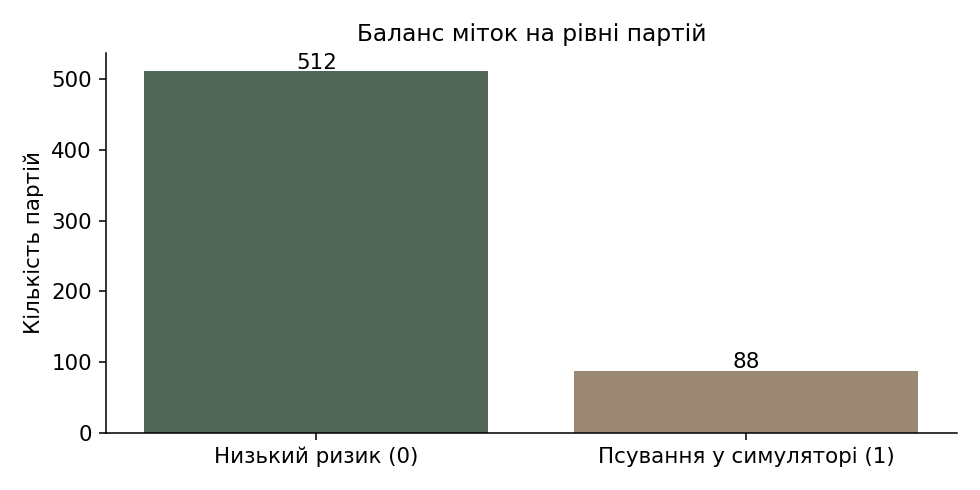

In [5]:
fig, ax = plt.subplots(figsize=(7,3.5))
counts=labels.simulated_spoilage.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Низький ризик (0)','Псування у симуляторі (1)'],counts,color=['#52665a','#9c8975'])
for i,v in enumerate(counts):ax.text(i,v+3,str(v),ha='center')
ax.set(ylabel='Кількість партій',title='Баланс міток на рівні партій')
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_classes.png');plt.close(fig)
print('Classes:',counts.to_dict(),'positive rate:',round(float(counts[1]/counts.sum()),4))


Оцінюємо F1 і recall позитивного класу; одна accuracy приховує дисбаланс. Вибір ваг класів виконується лише на навчальній частині.

Example shipment: 1


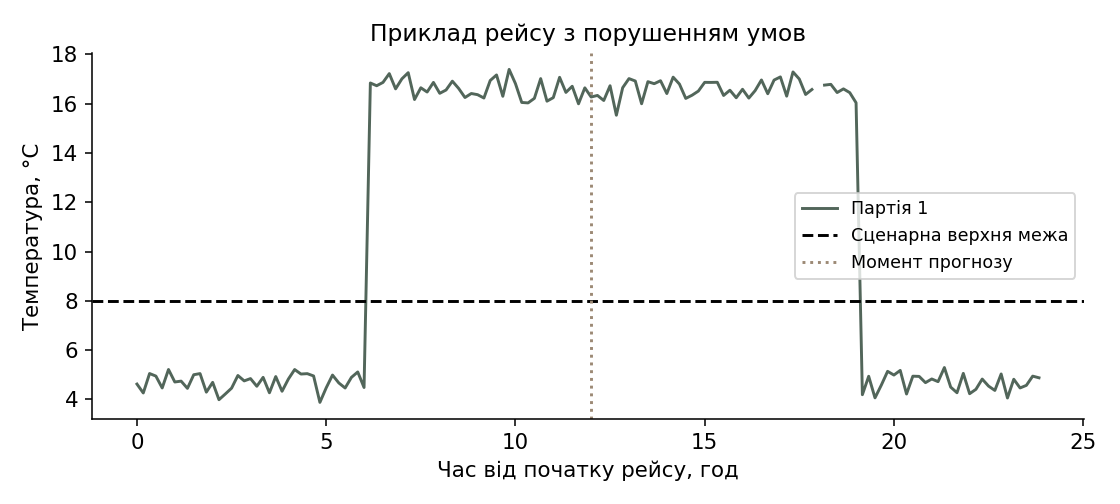

In [6]:
example = int(labels.loc[labels.simulated_spoilage==1,'shipment_id'].iloc[0])
series=clean.loc[clean.shipment_id==example]
fig,ax=plt.subplots(figsize=(8,3.6))
ax.plot(series.sample_index*DT,series.temperature_c,color='#52665a',label=f'Партія {example}')
ax.axhline(8,color='black',linestyle='--',label='Сценарна верхня межа')
ax.axvline(12,color='#9c8975',linestyle=':',label='Момент прогнозу')
ax.set(xlabel='Час від початку рейсу, год',ylabel='Температура, °C',title='Приклад рейсу з порушенням умов');ax.legend(fontsize=9)
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_timeseries.png');plt.close(fig)
print('Example shipment:',example)


Права частина ряду після 12 годин потрібна для формування результату симулятора, але недоступна прогнозній моделі. Перевірка цього обмеження виключає підглядання в майбутнє.

            parties  positive
split                        
test            120        16
train           360        53
validation      120        19
Features: ['temp_mean', 'temp_max', 'temp_std', 'humidity_mean', 'minutes_above8', 'degree_hours_above8', 'initial_age_h', 'missing_fraction']


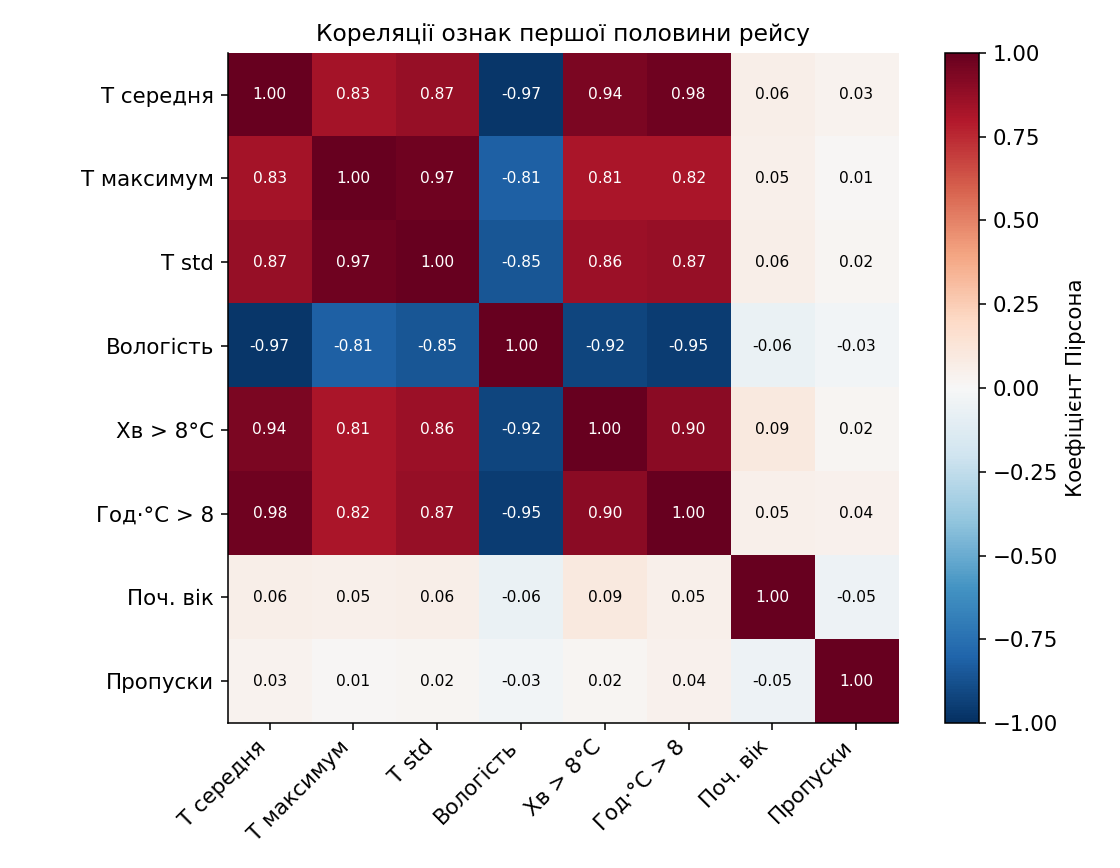

In [7]:
rows=[]
for b,g in clean[clean.sample_index<72].groupby('shipment_id',sort=True):
    t=g.temperature_c; h=g.humidity_pct
    rows.append(dict(shipment_id=b,temp_mean=t.mean(),temp_max=t.max(),temp_std=t.std(),humidity_mean=h.mean(),minutes_above8=int((t>8).sum())*10,degree_hours_above8=float((t-8).clip(lower=0).sum()*DT),initial_age_h=float(g.initial_age_h.iloc[0]),missing_fraction=float(t.isna().mean())))
features=pd.DataFrame(rows).merge(labels[['shipment_id','simulated_spoilage']],on='shipment_id',validate='one_to_one')
feature_cols=[x for x in features if x not in ['shipment_id','simulated_spoilage']]
assert 'latent_final_exposure' not in feature_cols
assert not features.shipment_id.duplicated().any()
features['split']=np.select([features.shipment_id<360,features.shipment_id<480],['train','validation'],default='test')
features.to_csv(ROOT/'data/processed/shipment_features.csv',index=False)
fig,ax=plt.subplots(figsize=(8,6.2))
corr=features[feature_cols].corr();im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1)
short=['T середня','T максимум','T std','Вологість','Хв > 8°C','Год·°C > 8','Поч. вік','Пропуски']
ax.set_xticks(range(8),short,rotation=45,ha='right');ax.set_yticks(range(8),short)
for i in range(8):
    for j in range(8):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if abs(corr.iloc[i,j])>.65 else 'black')
fig.colorbar(im,ax=ax,label='Коефіцієнт Пірсона');ax.set_title('Кореляції ознак першої половини рейсу')
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_correlation.png');plt.close(fig)
print(features.groupby('split').agg(parties=('shipment_id','size'),positive=('simulated_spoilage','sum')).to_string())
print('Features:',feature_cols)


Агрегати температури взаємозалежні; для логістичної регресії використовуємо L2-регуляризацію і стандартизацію. Ідентифікатор, split, мітка та повна прихована експозиція не входять у X.

Invalid sensor spikes removed: 231
Valid overheating observations retained: 14922


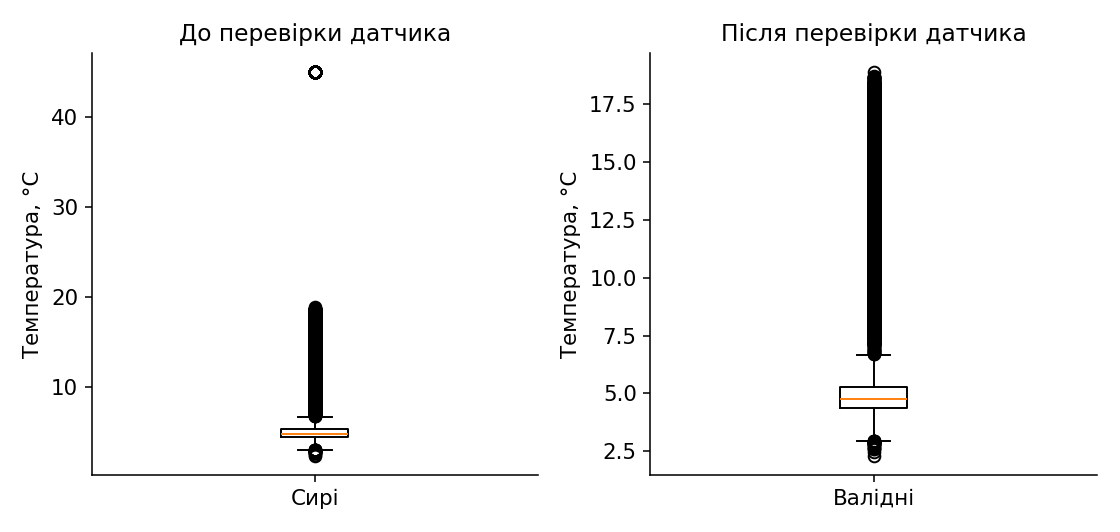

In [8]:
fig,ax=plt.subplots(1,2,figsize=(8,3.8))
ax[0].boxplot(raw.temperature_c.dropna(),tick_labels=['Сирі']);ax[0].set(ylabel='Температура, °C',title='До перевірки датчика')
ax[1].boxplot(clean.temperature_c.dropna(),tick_labels=['Валідні']);ax[1].set(ylabel='Температура, °C',title='Після перевірки датчика')
fig.tight_layout();fig.savefig(ROOT/'reports/figures/eda_outliers.png');plt.close(fig)
print('Invalid sensor spikes removed:',int(invalid.sum()))
print('Valid overheating observations retained:',int((clean.temperature_c>8).sum()))


Не видаляємо усі значення за правилом IQR: правий хвіст містить цільові порушення, а не лише збої. Видаляємо тільки явно змодельовані некоректні показники.

## 3 Попередній експеримент
Перші 360 партій — train, наступні 120 — validation, останні 120 — test. Партії однієї дати не перетинають межі. Пороги 30–240 хв та пороги ймовірності 0.20–0.80 обираються за F1 validation. Test відкривається один раз після фіксації порогів. Логістична регресія і Random Forest порівнюються з пороговим baseline; це додаткове завдання, а не перевірка інтегрованої системи.

             model  threshold  precision  recall     f1  roc_auc  validation_f1
          Baseline    100.000     0.2391  0.6875 0.3548   0.6683            NaN
LogisticRegression      0.625     0.6190  0.8125 0.7027   0.9597         0.6250
      RandomForest      0.425     0.4615  0.7500 0.5714   0.9345         0.6531
Class order [0,1]; RF confusion matrix: [[90, 14], [4, 12]]


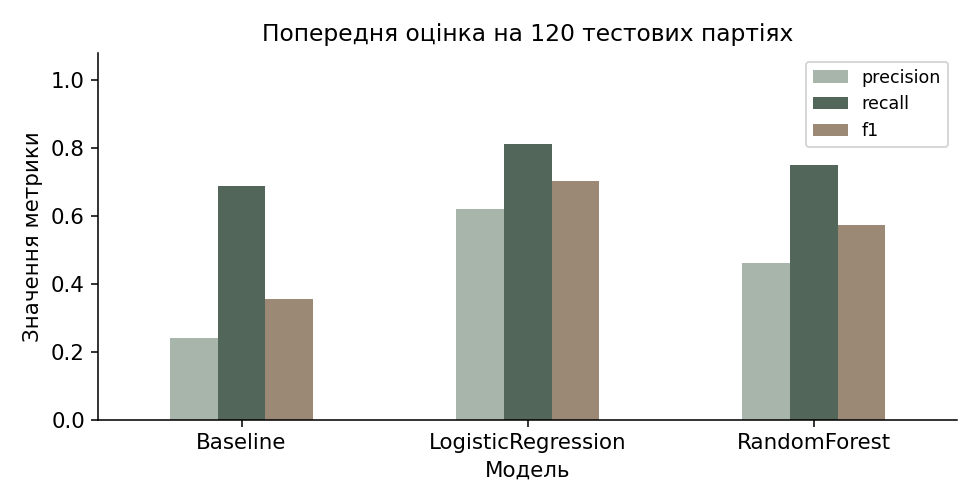

In [9]:
train=features[features.split=='train']; val=features[features.split=='validation']; test=features[features.split=='test']
assert set(train.shipment_id).isdisjoint(val.shipment_id) and set(train.shipment_id).isdisjoint(test.shipment_id)
models={
 'LogisticRegression':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced',random_state=24)),
 'RandomForest':make_pipeline(SimpleImputer(strategy='median'),RandomForestClassifier(n_estimators=200,max_depth=6,min_samples_leaf=5,class_weight='balanced',random_state=24,n_jobs=1))}
metrics=[];thresholds={}
baseline_threshold=max(range(30,241,10),key=lambda t:f1_score(val.simulated_spoilage,(val.minutes_above8>t).astype(int),zero_division=0))
baseline_pred=(test.minutes_above8>baseline_threshold).astype(int)
metrics.append(dict(model='Baseline',threshold=float(baseline_threshold),precision=precision_score(test.simulated_spoilage,baseline_pred,zero_division=0),recall=recall_score(test.simulated_spoilage,baseline_pred,zero_division=0),f1=f1_score(test.simulated_spoilage,baseline_pred,zero_division=0),roc_auc=roc_auc_score(test.simulated_spoilage,test.minutes_above8)))
for name,model in models.items():
    model.fit(train[feature_cols],train.simulated_spoilage)
    vp=model.predict_proba(val[feature_cols])[:,1]
    threshold=max(np.arange(.2,.801,.025),key=lambda t:f1_score(val.simulated_spoilage,(vp>=t).astype(int),zero_division=0))
    thresholds[name]=float(threshold)
    score=model.predict_proba(test[feature_cols])[:,1]; pred=(score>=threshold).astype(int)
    metrics.append(dict(model=name,threshold=float(threshold),validation_f1=f1_score(val.simulated_spoilage,(vp>=threshold).astype(int),zero_division=0),precision=precision_score(test.simulated_spoilage,pred,zero_division=0),recall=recall_score(test.simulated_spoilage,pred,zero_division=0),f1=f1_score(test.simulated_spoilage,pred,zero_division=0),roc_auc=roc_auc_score(test.simulated_spoilage,score)))
metrics_df=pd.DataFrame(metrics)
print(metrics_df.round(4).to_string(index=False))
print('Class order [0,1]; RF confusion matrix:',confusion_matrix(test.simulated_spoilage,(models['RandomForest'].predict_proba(test[feature_cols])[:,1]>=thresholds['RandomForest']).astype(int)).tolist())
fig,ax=plt.subplots(figsize=(7,3.6))
metrics_df.set_index('model')[['precision','recall','f1']].plot.bar(ax=ax,color=['#a7b5aa','#52665a','#9c8975'])
ax.set(ylim=(0,1.08),ylabel='Значення метрики',xlabel='Модель',title='Попередня оцінка на 120 тестових партіях');ax.tick_params(axis='x',rotation=0);ax.legend(fontsize=9)
fig.tight_layout();fig.savefig(ROOT/'reports/figures/model_metrics.png');plt.close(fig)
summary={'seed':24,'raw_rows':len(raw),'shipments':len(labels),'positive':int(labels.simulated_spoilage.sum()),'missing_before':{k:int(v) for k,v in raw[cols].isna().sum().items()},'missing_after':{k:int(v) for k,v in clean[cols].isna().sum().items()},'spikes':int(invalid.sum()),'overheat_valid':int((clean.temperature_c>8).sum()),'split_counts':features.groupby('split').simulated_spoilage.agg(['size','sum']).to_dict('index'),'metrics':metrics,'rf_confusion':confusion_matrix(test.simulated_spoilage,(models['RandomForest'].predict_proba(test[feature_cols])[:,1]>=thresholds['RandomForest']).astype(int)).tolist(),'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':__import__('sklearn').__version__,'matplotlib':__import__('matplotlib').__version__}}
(ROOT/'reports/results/summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))


## Висновки
Усі результати стосуються тільки цього генератора й розбиття. Без зовнішнього набору та мікробіологічних міток якість на реальних перевезеннях невідома. Перед ЛР 4 потрібні тести на зміні частоти/амплітуди порушень, пропусках 5–10%, bootstrap за партіями та перевірка калібрування. Цільові F1/recall у вимогах є критеріями наступних експериментів, а не обіцянкою досягнення.